In [ ]:
# =====================================================================
# SEL 0: INSTALASI MODUL
# =====================================================================
!pip install osmnx rasterio matplotlib networkx

In [ ]:
# =====================================================================
# SEL 1: DEKLARASI SELURUH PUSTAKA (ALL MODULE IMPORTS)
# =====================================================================
import os
import sys
import json
import time
import heapq
import tracemalloc
import random
import osmnx as ox
import networkx as nx
import rasterio
import numpy as np
import pandas as pd
from IPython.display import display
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as colors

print("[SYSTEM STATUS: ALL MODULES LOADED SUCCESS]")

[SYSTEM STATUS: ALL MODULES LOADED SUCCESS]


In [ ]:
# =====================================================================
# SEL 2: GLOBAL CONFIGURATION PARAMETERS
# =====================================================================
GLOBAL_CONFIG = {
    "WAKTU_BERANGKAT_MENIT": 60.0,            # Agen mulai bergerak pada menit ke-60

    "MOBIL_KECEPATAN_NORMAL_MPS": 8.33,       # 30 km/jam dalam meter/detik
    "MOBIL_THRESHOLD_BANJIR_METER": 0.40,     # Batas kritis knalpot mobil kecil (40 cm)

    "PEJALAN_KECEPATAN_NORMAL_MPS": 1.11,     # 4 km/jam dalam meter/detik
}

print("[SYSTEM STATUS: GLOBAL CONFIGURATION LOCKED]")

[SYSTEM STATUS: GLOBAL CONFIGURATION LOCKED]


In [ ]:
# =====================================================================
# SEL 3: LOADING JARINGAN SPASIAL DATA & RUN DISKRET PASANG SURUT CSV
# =====================================================================
# 1. Jalur Direktori Dataset
path_csv_pasang = '/content/drive/MyDrive/Kuliah/Proyek ASA/04_Notebook/dataset/chart_data.csv'
path_demnas = '/content/drive/MyDrive/Kuliah/Proyek ASA/04_Notebook/dataset/DEMNAS_1409-22_v1.0.tif'

# 2. Akuisisi Vektor Graf Jalan 6 Kecamatan Pesisir Semarang
print("1. Memulai scraping jaringan jalan 6 kecamatan pesisir Semarang...")
enam_kecamatan = [
    # "Tugu, Semarang, Central Java, Indonesia",
    # "Semarang Barat, Semarang, Central Java, Indonesia",
    "Semarang Utara, Semarang, Central Java, Indonesia",
    "Semarang Timur, Central Java, Indonesia",
    "Gayamsari, Semarang, Central Java, Indonesia",
    # "Genuk, Semarang, Central Java, Indonesia"
]
G_raw = ox.graph_from_place(enam_kecamatan, network_type='drive')
print(f"   -> Graf Berhasil Diunduh. Nodes: {len(G_raw.nodes)}, Edges: {len(G_raw.edges)}")
print("-" * 70)

# 3. Spatial Join: Sampling Elevasi Grid DEMNAS ke Nodes Graf Geografis (WGS84)
print("2. Memulai proses Spatial Join dengan DEMNAS (Datum Vertikal EGM2008)...")
nodes_teruji = 0
nodes_fallback = 0

try:
    with rasterio.open(path_demnas) as dem_data:
        crs_info = dem_data.crs if dem_data.crs else "Geographic WGS84 (Default BIG)"
        print(f"   -> Metadata DEMNAS Loaded. CRS: {crs_info}")

        for node_id, data in G_raw.nodes(data=True):
            lon, lat = data['x'], data['y']
            raster_sample = dem_data.sample([(lon, lat)])
            val_elevasi = next(raster_sample)[0]

            # Filter piksel kosong (NoData) pada batas lembar peta (NLP)
            if np.isnan(val_elevasi) or val_elevasi < -10.0 or val_elevasi > 150.0:
                G_raw.nodes[node_id]['elevation'] = 1.0  # Fallback pesisir pantai rendah
                nodes_fallback += 1
            else:
                G_raw.nodes[node_id]['elevation'] = float(val_elevasi)
                nodes_teruji += 1
    print(f"   -> Spatial Join Sukses. Elevasi Asli: {nodes_teruji}, Fallback: {nodes_fallback}")
except FileNotFoundError:
    print(f"   [!] WARNING: Berkas DEMNAS tidak ditemukan di {path_demnas}. Menggunakan dummy 1.2m.")
    for node_id in G_raw.nodes:
        G_raw.nodes[node_id]['elevation'] = 1.2

print("-" * 70)

# 4. Proyeksikan Graf ke Satuan Meter (UTM Zone 49S) untuk Kalkulasi Rute Meter
print("3. Memproyeksikan Graf ke Satuan Meter...")
G = ox.project_graph(G_raw)

# 5. Memuat Data Temporal Pasang Surut Air Laut (Kolom EST)
print("4. Memuat dataset pasang surut waktu nyata (Kolom EST)...")
try:
    df_pasang = pd.read_csv(path_csv_pasang)
    # Mapping berbasis kelipatan indeks 10 menit (0, 10, 20, 30, dst)
    df_pasang['menit_simulasi'] = np.arange(len(df_pasang)) * 10
    dict_pasang_est = pd.Series(df_pasang.EST.values, index=df_pasang.menit_simulasi).to_dict()
    print("   [STATUS: CSV LOADED SUCCESS] Dictionary pencarian cepat O(1) terbentuk.")
except FileNotFoundError:
    print(f"   [!] ERROR: Berkas CSV di {path_csv_pasang} tidak ditemukan. Fallback diaktifkan.")
    dict_pasang_est = {m: 1.55 for m in range(0, 1440, 10)}

print("-" * 70)
print("[SYSTEM STATUS: DATA ACQUISITION & PREPROCESSING STAGE READY]")

1. Memulai scraping jaringan jalan 6 kecamatan pesisir Semarang...
   -> Graf Berhasil Diunduh. Nodes: 4412, Edges: 11933
----------------------------------------------------------------------
2. Memulai proses Spatial Join dengan DEMNAS (Datum Vertikal EGM2008)...
   -> Metadata DEMNAS Loaded. CRS: Geographic WGS84 (Default BIG)
   -> Spatial Join Sukses. Elevasi Asli: 4313, Fallback: 99
----------------------------------------------------------------------
3. Memproyeksikan Graf ke Satuan Meter...
4. Memuat dataset pasang surut waktu nyata (Kolom EST)...
   [STATUS: CSV LOADED SUCCESS] Dictionary pencarian cepat O(1) terbentuk.
----------------------------------------------------------------------
[SYSTEM STATUS: DATA ACQUISITION & PREPROCESSING STAGE READY]


In [ ]:
# =====================================================================
# SEL 4: ATURAN DIKRETIZASI BANJIR DAN ALGORITMA PENATAAN JALUR
# =====================================================================
def hitung_kedalaman_rob_node(node_id, menit_simulasi, graf_jalan):
    """Mencari tinggi genangan air di jalan raya secara spasio-temporal O(1)"""
    elevasi_tanah = graf_jalan.nodes[node_id]['elevation']
    menit_terdekat = int(round(menit_simulasi / 10.0) * 10)
    max_menit = max(dict_pasang_est.keys())
    menit_lookup = min(menit_terdekat, max_menit)
    tinggi_air_laut = dict_pasang_est.get(menit_lookup, 0.0)
    return max(0.0, tinggi_air_laut - elevasi_tanah)

def hitung_faktor_penalti(kedalaman_air):
    """Matriks Aturan Penalti Hambatan Fisis Kebencanaan (Phi)"""
    if kedalaman_air < 0.20:
        return 1.0          # Kondisi Kering / Aman
    elif 0.20 <= kedalaman_air <= 0.40:
        return 2.5          # Kecepatan Melambat Bergenang
    else:
        return float('inf') # Jalan Lumpuh / Buntu Total

def hitung_heuristik_haversine(G, n1, n2):
    """Fungsi h(n): Jarak Euclidean murni berbasis koordinat UTM planar meter"""
    x1, y1 = G.nodes[n1]['x'], G.nodes[n1]['y']
    x2, y2 = G.nodes[n2]['x'], G.nodes[n2]['y']
    return np.sqrt((x1 - x2)**2 + (y1 - y2)**2)

def hitung_exposure_score(path, waktu_mulai, v_normal, graf):
    """Mengukur total akumulasi kedalaman banjir yang diderita agen sepanjang jalur"""
    if not path: return 0.0
    total_flood = 0.0
    curr_time = waktu_mulai
    for i in range(len(path) - 1):
        u, v = path[i], path[i+1]
        edge_length = graf[u][v][0]['length']
        depth = hitung_kedalaman_rob_node(v, curr_time, graf)
        total_flood += depth
        penalti = hitung_faktor_penalti(depth)
        curr_time += edge_length / (v_normal / (penalti if penalti != float('inf') else 100.0))
    return total_flood

# --- IMPLEMENTASI TIGA STRATEGI ALGORITMA PENATAAN JALUR ---

def standard_astar_search(G, start_node, target_node, start_time, v_normal):
    """Standard A* mencari lintasan terpendek statis (Buta Banjir)"""
    open_list = []
    g_score = {node: float('inf') for node in G.nodes}
    g_score[start_node] = 0.0
    heapq.heappush(open_list, (hitung_heuristik_haversine(G, start_node, target_node), start_node, start_time))
    explored_nodes = set()
    parent_map = {}

    while open_list:
        f_curr, curr_node, curr_time = heapq.heappop(open_list)
        explored_nodes.add(curr_node)
        if curr_node == target_node:
            path = []
            temp = curr_node
            while temp in parent_map:
                path.append(temp)
                temp = parent_map[temp]
            path.append(start_node)
            path = path[::-1]
            timestamps = [start_time]
            t = start_time
            for i in range(len(path) - 1):
                t += G[path[i]][path[i+1]][0]['length'] / v_normal
                timestamps.append(t)
            return path, g_score[target_node], explored_nodes, timestamps

        for neighbor in G[curr_node]:
            edge_length = G[curr_node][neighbor][0]['length']
            tentative_g = g_score[curr_node] + edge_length
            if tentative_g < g_score[neighbor]:
                parent_map[neighbor] = curr_node
                g_score[neighbor] = tentative_g
                f_score = tentative_g + hitung_heuristik_haversine(G, neighbor, target_node)
                heapq.heappush(open_list, (f_score, neighbor, curr_time + (edge_length / v_normal)))
    return None, float('inf'), explored_nodes, []

def branch_and_bound_search(G, start_node, target_node, start_time, v_normal, h_threshold):
    """Branch and Bound melakukan penelusuran pohon status dengan pemangkasan kaku"""
    stack = [(0.0, start_node, start_time, [start_node])]
    best_cost, best_path = float('inf'), None
    visited_costs = {node: float('inf') for node in G.nodes}
    visited_costs[start_node] = 0.0
    explored_count = 0

    while stack:
        curr_cost, curr_node, curr_time, curr_path = stack.pop()
        explored_count += 1
        if curr_node == target_node:
            if curr_cost < best_cost:
                best_cost, best_path = curr_cost, curr_path
            continue

        for neighbor in G[curr_node]:
            edge_length = G[curr_node][neighbor][0]['length']
            kedalaman = hitung_kedalaman_rob_node(neighbor, curr_time, G)
            if kedalaman > h_threshold: continue
            penalti = hitung_faktor_penalti(kedalaman)
            if penalti == float('inf'): continue

            next_cost = curr_cost + (edge_length * penalti)
            if next_cost >= best_cost or next_cost >= visited_costs[neighbor]: continue

            visited_costs[neighbor] = next_cost
            stack.append((next_cost, neighbor, curr_time + (edge_length / (v_normal / penalti)), curr_path + [neighbor]))
    return best_path, best_cost, explored_count

def time_dependent_custom_astar(G, start_node, target_node, start_time, v_normal, h_threshold):
    """Proposed Model: Time-Dependent Customized A* (Adaptif Spasio-Temporal)"""
    open_list = []
    g_score = {node: float('inf') for node in G.nodes}
    g_score[start_node] = 0.0
    heapq.heappush(open_list, (hitung_heuristik_haversine(G, start_node, target_node), start_node, start_time))
    explored_nodes = set()
    parent_map = {}

    while open_list:
        f_curr, curr_node, curr_time = heapq.heappop(open_list)
        explored_nodes.add(curr_node)
        if curr_node == target_node:
            path = []
            temp = curr_node
            while temp in parent_map:
                path.append(temp)
                temp = parent_map[temp]
            path.append(start_node)
            path = path[::-1]
            timestamps = [start_time]
            t = start_time
            for i in range(len(path) - 1):
                penalti = hitung_faktor_penalti(hitung_kedalaman_rob_node(path[i+1], t, G))
                t += G[path[i]][path[i+1]][0]['length'] / (v_normal / penalti)
                timestamps.append(t)
            return path, g_score[target_node], explored_nodes, timestamps

        for neighbor in G[curr_node]:
            edge_length = G[curr_node][neighbor][0]['length']
            kedalaman = hitung_kedalaman_rob_node(neighbor, curr_time, G)
            if kedalaman > h_threshold: continue
            penalti = hitung_faktor_penalti(kedalaman)
            if penalti == float('inf'): continue

            tentative_g = g_score[curr_node] + (edge_length * penalti)
            if tentative_g < g_score[neighbor]:
                parent_map[neighbor] = curr_node
                g_score[neighbor] = tentative_g
                f_score = tentative_g + hitung_heuristik_haversine(G, neighbor, target_node)
                heapq.heappush(open_list, (f_score, neighbor, curr_time + (edge_length / (v_normal / penalti))))
    return None, float('inf'), explored_nodes, []

# Registrasi Lokasi Posko Evakuasi Taktis (Internal Graf)
posko_internal_real = {
    "P5_GOR_USM": (110.4519, -6.9809), "P6_Masjid_Trimulyo": (110.4786, -6.9499),
    "P_Rejomulyo_Balai": (110.4349, -6.9643), "P8_Kemijen_Kantor": (110.4387, -6.9594),
    "P9_Mlatiharjo_Kantor": (110.4407, -6.9650), "P10_Mlatibaru_Kantor": (110.4382, -6.9646)
}
posko_node_ids = {name: ox.nearest_nodes(G_raw, X=c[0], Y=c[1]) for name, c in posko_internal_real.items()}
print("[SYSTEM STATUS: ROUTING CORES AND SHELTERS LOADED SUCCESS]")

[SYSTEM STATUS: ROUTING CORES AND SHELTERS LOADED SUCCESS]


In [ ]:
# =====================================================================
# SEL 5: SAMPLING AGEN ACAK BERSYARAT (SEMARANG UTARA LOW ELEVATION)
# =====================================================================
import json
import random

print("============================================================")
print("5. MEMULAI SAMPLING NODE START ACAK DI ZONA EKSTREM UTARA   ")
print("============================================================")

# 1. Memfilter seluruh node dalam graf yang elevasinya sangat rendah (Threshold <= 1.0 meter)
# Serta berada di area koordinat geografis Semarang Utara (Bounding Box area pesisir)
kandidat_acak_utara = []

for node_id, data in G_raw.nodes(data=True):
    # Mengambil koordinat sebelum proyeksi untuk validasi posisi geografis lat/lon
    lon, lat = data['x'], data['y']
    elevasi = data.get('elevation', 0.0)

    # Batasan Bounding Box khusus untuk kluster area Semarang Utara bagian pesisir/pelabuhan
    if (lat >= -6.9600 and lat <= -6.9350) and (lon >= 110.4000 and lon <= 110.4400):
        if elevasi <= 1.0: # Threshold ketinggian tanah fisis ekstrem rawan tenggelam
            kandidat_acak_utara.append(node_id)

# Fallback proteksi jika tidak ada node yang lolos filter ketat bounding box
if not kandidat_acak_utara:
    print("   [!] Kriteria ketat tidak terpenuhi, melonggarkan filter lokasi...")
    kandidat_acak_utara = [node for node, data in G_raw.nodes(data=True) if data.get('elevation', 0.0) <= 1.0]

# 2. Mengambil 1 simpul secara acak bersyarat
# Seed dikunci pada angka 12 agar titik yang terpilih konsisten saat pengujian ulang
random.seed(12)
node_start_fix = random.choice(kandidat_acak_utara)

# 3. Ambil ID Node tujuan tetap dari penampung variabel Sel 3 (P Rejomulyo Balai)
node_dest_fix = posko_node_ids["P_Rejomulyo_Balai"]

# 4. Konstruksi berkas json data agen tunggal
dataset_tunggal_representatif = [{
    "id_agen": 1,
    "jenis_agen": "mobil_kecil",
    "node_start": int(node_start_fix),
    "node_destination": int(node_dest_fix)
}]

# 5. Menulis data ke file lokal runtime
with open('dataset_mini_evakuasi.json', 'w') as f_json:
    json.dump(dataset_tunggal_representatif, f_json, indent=2)

print("-" * 70)
print(f"[STATUS: SUCCESS] 1 Agen Acak Semarang Utara Berhasil Dikunci!")
print(f" -> Terpilih Node ID Asal : {node_start_fix}")
print(f" -> Terpilih Node ID Tuju : {node_dest_fix} (P Rejomulyo Balai)")
print("============================================================")

5. MEMULAI SAMPLING NODE START ACAK DI ZONA EKSTREM UTARA   
----------------------------------------------------------------------
[STATUS: SUCCESS] 1 Agen Acak Semarang Utara Berhasil Dikunci!
 -> Terpilih Node ID Asal : 5466033683
 -> Terpilih Node ID Tuju : 3230468534 (P Rejomulyo Balai)


In [ ]:
# =====================================================================
# SEL 6: ENGINE SIMULASI DAN EKSTRAKSI DATA DESKRIPTIF GEOGRAFIS
# =====================================================================
with open('dataset_mini_evakuasi.json', 'r') as f:
    daftar_agen = json.load(f)

KOTAK_VISUALISASI_FIGURES = {
    "Skenario 2": {"Standard_A*": {"paths": [], "explored": [], "times": []}, "Custom_TD_A*": {"paths": [], "explored": [], "times": []}}
}
id_sampel_mobil = 1

hasil_summary = {
    "Skenario 2 (Mobil Kecil)": {
        "Standard_A*": {"time": [], "explored": [], "memory": [], "length": [], "flood": [], "success": 0},
        "Branch_Bound": {"time": [], "explored": [], "memory": [], "length": [], "flood": [], "success": 0},
        "Custom_TD_A*": {"time": [], "explored": [], "memory": [], "length": [], "flood": [], "success": 0}
    }
}

for agen in daftar_agen:
    id_a, n_start, n_dest = agen["id_agen"], agen["node_start"], agen["node_destination"]
    v_norm = GLOBAL_CONFIG["MOBIL_KECEPATAN_NORMAL_MPS"]
    h_thresh = GLOBAL_CONFIG["MOBIL_THRESHOLD_BANJIR_METER"]
    t_start = GLOBAL_CONFIG["WAKTU_BERANGKAT_MENIT"]

    # --- 1. STANDARD A* ---
    tracemalloc.start()
    start_tic = time.perf_counter()
    path_sa, cost_sa, exp_sa, times_sa = standard_astar_search(G, n_start, n_dest, t_start, v_norm)
    _, peak_mem_sa = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    if path_sa:
        hasil_summary["Skenario 2 (Mobil Kecil)"]["Standard_A*"]["time"].append((time.perf_counter() - start_tic) * 1000)
        hasil_summary["Skenario 2 (Mobil Kecil)"]["Standard_A*"]["explored"].append(len(exp_sa))
        hasil_summary["Skenario 2 (Mobil Kecil)"]["Standard_A*"]["memory"].append(peak_mem_sa / 1024)
        hasil_summary["Skenario 2 (Mobil Kecil)"]["Standard_A*"]["length"].append(cost_sa / 1000)
        hasil_summary["Skenario 2 (Mobil Kecil)"]["Standard_A*"]["flood"].append(hitung_exposure_score(path_sa, t_start, v_norm, G))
        if max([hitung_kedalaman_rob_node(n, t_start, G) for n in path_sa]) <= h_thresh:
            hasil_summary["Skenario 2 (Mobil Kecil)"]["Standard_A*"]["success"] += 1
        KOTAK_VISUALISASI_FIGURES["Skenario 2"]["Standard_A*"]["paths"] = path_sa
        KOTAK_VISUALISASI_FIGURES["Skenario 2"]["Standard_A*"]["explored"] = list(exp_sa)
        KOTAK_VISUALISASI_FIGURES["Skenario 2"]["Standard_A*"]["times"] = times_sa

    # --- 2. CUSTOM TD-A* (PROPOSED) ---
    tracemalloc.start()
    start_tic = time.perf_counter()
    path_td, cost_td, exp_td, times_td = time_dependent_custom_astar(G, n_start, n_dest, t_start, v_norm, h_thresh)
    _, peak_mem_td = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    if path_td:
        hasil_summary["Skenario 2 (Mobil Kecil)"]["Custom_TD_A*"]["time"].append((time.perf_counter() - start_tic) * 1000)
        hasil_summary["Skenario 2 (Mobil Kecil)"]["Custom_TD_A*"]["explored"].append(len(exp_td))
        hasil_summary["Skenario 2 (Mobil Kecil)"]["Custom_TD_A*"]["memory"].append(peak_mem_td / 1024)
        hasil_summary["Skenario 2 (Mobil Kecil)"]["Custom_TD_A*"]["length"].append(sum([G[path_td[i]][path_td[i+1]][0]['length'] for i in range(len(path_td)-1)]) / 1000.0)
        hasil_summary["Skenario 2 (Mobil Kecil)"]["Custom_TD_A*"]["flood"].append(hitung_exposure_score(path_td, t_start, v_norm, G))
        hasil_summary["Skenario 2 (Mobil Kecil)"]["Custom_TD_A*"]["success"] += 1
        KOTAK_VISUALISASI_FIGURES["Skenario 2"]["Custom_TD_A*"]["paths"] = path_td
        KOTAK_VISUALISASI_FIGURES["Skenario 2"]["Custom_TD_A*"]["explored"] = list(exp_td)
        KOTAK_VISUALISASI_FIGURES["Skenario 2"]["Custom_TD_A*"]["times"] = times_td

    # --- 3. BRANCH & BOUND (EXACT CONTROL) ---
    tracemalloc.start()
    start_tic = time.perf_counter()
    rute_bb, cost_bb, exp_bb = branch_and_bound_search(G, n_start, n_dest, t_start, v_norm, h_thresh)
    _, peak_mem_bb = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    if rute_bb:
        hasil_summary["Skenario 2 (Mobil Kecil)"]["Branch_Bound"]["time"].append((time.perf_counter() - start_tic) * 1000)
        hasil_summary["Skenario 2 (Mobil Kecil)"]["Branch_Bound"]["explored"].append(exp_bb)
        hasil_summary["Skenario 2 (Mobil Kecil)"]["Branch_Bound"]["memory"].append(peak_mem_bb / 1024)
        hasil_summary["Skenario 2 (Mobil Kecil)"]["Branch_Bound"]["length"].append(sum([G[rute_bb[i]][rute_bb[i+1]][0]['length'] for i in range(len(rute_bb)-1)]) / 1000.0)
        hasil_summary["Skenario 2 (Mobil Kecil)"]["Branch_Bound"]["flood"].append(hitung_exposure_score(rute_bb, t_start, v_norm, G))
        hasil_summary["Skenario 2 (Mobil Kecil)"]["Branch_Bound"]["success"] += 1

print("\n[STATUS: EVALUASI METRIK SELESAI]")
print("-" * 80)

# REKAP DATA KE TABEL 2 INDEPENDEN
rows_tabel = []
for skenario, algos in hasil_summary.items():
    for algo_name, metrics in algos.items():
        sc = metrics["success"]
        rows_tabel.append([
            skenario, algo_name,
            f"{np.mean(metrics['time']):.2f} ms" if metrics['time'] else "0.00 ms",
            f"{np.mean(metrics['explored']):.1f} nodes" if metrics['explored'] else "0.0 nodes",
            f"{max(metrics['memory']):.2f} KB" if metrics['memory'] else "0.00 KB",
            f"{np.mean(metrics['length']):.2f} km" if metrics['length'] else "0.00 km",
            f"{np.mean(metrics['flood']):.4f} m" if metrics['flood'] else "0.0000 m",
            f"{(sc / 1) * 100:.2f}%"
        ])

df_tabel_2 = pd.DataFrame(rows_tabel, columns=["Skenario Pengujian", "Algoritma", "Running Time (Mean)", "Explored Nodes (Mean)", "Peak Memory (Max)", "Path Length (Mean)", "Flood Exposure (Mean)", "Success Rate"])
display(df_tabel_2)

# =====================================================================
# BLOK EXTRA: DATA DESKRIPTIF GEOGRAFIS AGEN TUNGGAL SINKRON CSV
# =====================================================================
print("\n" + "="*80)
print("                    DATA DESKRIPTIF GEOGRAFIS AGEN EVAKUASI                    ")
print("="*80)

coord_start_x, coord_start_y = G_raw.nodes[node_start_fix]['x'], G_raw.nodes[node_start_fix]['y']
coord_dest_x, coord_dest_y = G_raw.nodes[node_dest_fix]['x'], G_raw.nodes[node_dest_fix]['y']
elev_start = G_raw.nodes[node_start_fix].get('elevation', 0.0)
elev_dest = G_raw.nodes[node_dest_fix].get('elevation', 0.0)

print(f"1. TITIK ASAL DARURAT (START NODE)")
print(f"   - ID Node Graf Transportasi : {node_start_fix}")
print(f"   - Koordinat Geografis       : Latitude {coord_start_y:.6f}, Longitude {coord_start_x:.6f}")
print(f"   - Wilayah Kunci Sampling    : Sektor Rendahan Acak Semarang Utara (Threshold <= 1.0m)")
print(f"   - Ketinggian Tanah (DEMNAS) : {elev_start:.2f} meter di atas permukaan laut")
print("-" * 80)
print(f"2. TITIK TUJUAN PENYELAMATAN (DESTINATION NODE)")
print(f"   - ID Node Graf Transportasi : {node_dest_fix}")
print(f"   - Koordinat Geografis       : Latitude {coord_dest_y:.6f}, Longitude {coord_dest_x:.6f}")
print(f"   - Nama Shelter Resmi        : P Balai Desa Rejomulyo (Kecamatan Semarang Timur)")
print(f"   - Ketinggian Tanah (DEMNAS) : {elev_dest:.2f} meter di atas permukaan laut")
print("="*80)


[STATUS: EVALUASI METRIK SELESAI]
--------------------------------------------------------------------------------


,Skenario Pengujian,Algoritma,Running Time (Mean),Explored Nodes (Mean),Peak Memory (Max),Path Length (Mean),Flood Exposure (Mean),Success Rate
0,Skenario 2 (Mobil Kecil),Standard_A*,31.61 ms,576.0 nodes,307.79 KB,3.17 km,2.1209 m,0.00%
1,Skenario 2 (Mobil Kecil),Branch_Bound,68631.04 ms,219530.0 nodes,363.02 KB,5.88 km,0.4781 m,100.00%
2,Skenario 2 (Mobil Kecil),Custom_TD_A*,174.52 ms,559.0 nodes,306.26 KB,5.94 km,0.0830 m,100.00%



                    DATA DESKRIPTIF GEOGRAFIS AGEN EVAKUASI                    
1. TITIK ASAL DARURAT (START NODE)
   - ID Node Graf Transportasi : 5466033683
   - Koordinat Geografis       : Latitude -6.957556, Longitude 110.413543
   - Wilayah Kunci Sampling    : Sektor Rendahan Acak Semarang Utara (Threshold <= 1.0m)
   - Ketinggian Tanah (DEMNAS) : 0.64 meter di atas permukaan laut
--------------------------------------------------------------------------------
2. TITIK TUJUAN PENYELAMATAN (DESTINATION NODE)
   - ID Node Graf Transportasi : 3230468534
   - Koordinat Geografis       : Latitude -6.964804, Longitude 110.434811
   - Nama Shelter Resmi        : P Balai Desa Rejomulyo (Kecamatan Semarang Timur)
   - Ketinggian Tanah (DEMNAS) : 2.41 meter di atas permukaan laut


  MEMULAI PROSES RENDERING PETA DASAR SPASIAL (FIGURE 3)    


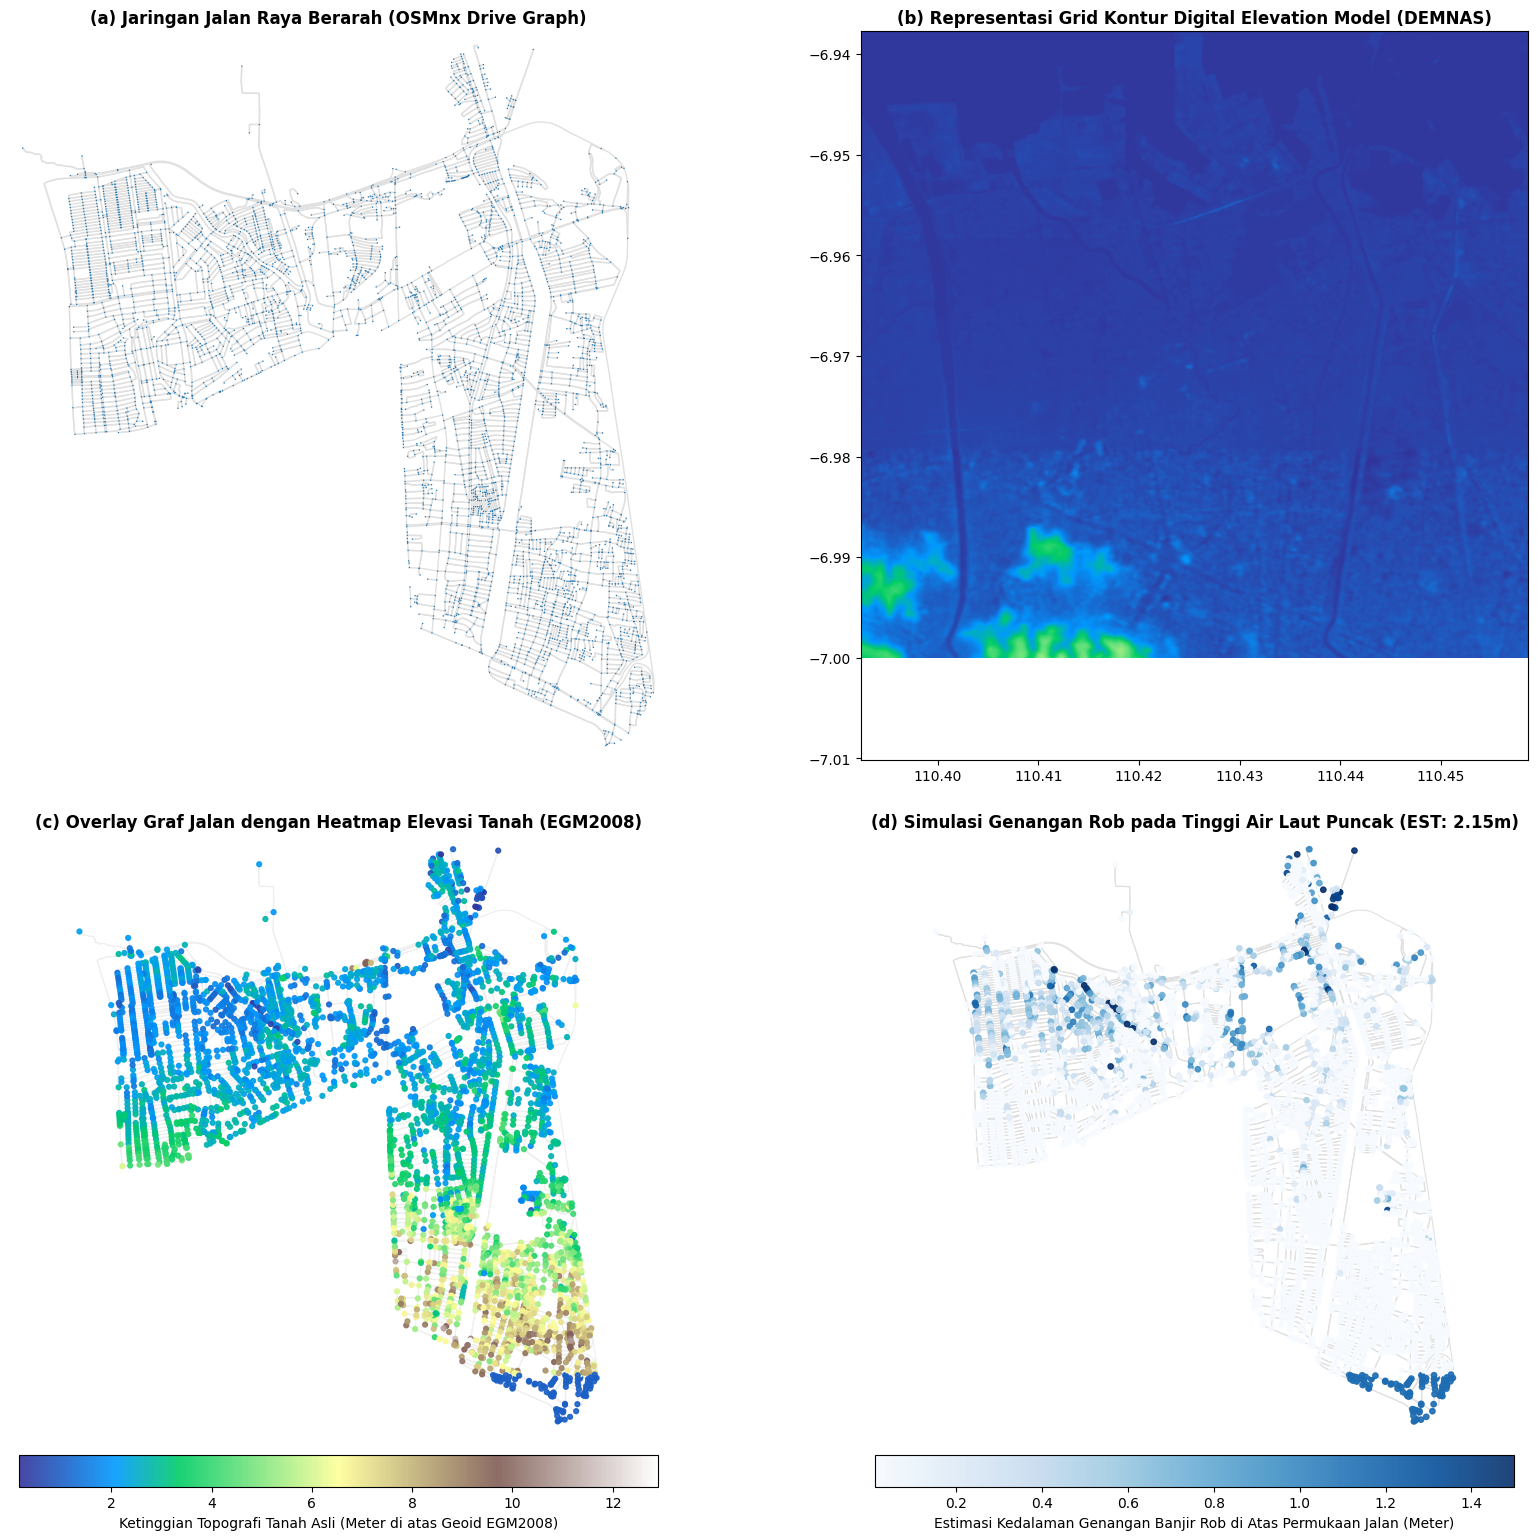

[STATUS VISUALISASI: FIGURE 3 TERIMPAN SEBAGAI 'Figure_3_visualisasi_komponen_spasial_semarang.png']


In [ ]:
# =====================================================================
# SEL 7: GEOSPATIAL VISUALIZATION CORES (UNTUK FIGURE 3)
# =====================================================================
print("============================================================")
print("  MEMULAI PROSES RENDERING PETA DASAR SPASIAL (FIGURE 3)    ")
print("============================================================")

# 1. Sinkronisasi Titik Ekstraksi Koordinat Vektor Graf
node_utm_x = [G.nodes[node]['x'] for node in G.nodes]
node_utm_y = [G.nodes[node]['y'] for node in G.nodes]
node_elevations = [G.nodes[node]['elevation'] for node in G.nodes]

# 2. Ekstraksi Waktu Menggunakan Kondisi Tinggi Air Puncak Eksisting CSV (EST Maksimum)
menit_puncak_est = max(dict_pasang_est.keys(), key=lambda k: dict_pasang_est[k])
tinggi_puncak_est = dict_pasang_est[menit_puncak_est]

node_water_depths = [hitung_kedalaman_rob_node(node, menit_puncak_est, G) for node in G.nodes]

# 3. Inisialisasi Kanvas Plot Utama (2 Baris x 2 Kolom)
fig3, axes3 = plt.subplots(2, 2, figsize=(18, 16))
ax1, ax2, ax3, ax4 = axes3.flatten()

# --- SUB-PLOT 3(a): JARINGAN JALAN RAYA VEKTOR MURNI ---
ax1.set_title("(a) Jaringan Jalan Raya Berarah (OSMnx Drive Graph)", fontsize=12, fontweight='bold')
ox.plot_graph(G, ax=ax1, node_size=1, node_color='#1f77b4', edge_color='#e0e0e0', bgcolor='white', show=False, close=False)

# --- SUB-PLOT 3(b): RASTER GRID ORIGINAL DEMNAS ---
ax2.set_title("(b) Representasi Grid Kontur Digital Elevation Model (DEMNAS)", fontsize=12, fontweight='bold')
try:
    with rasterio.open(path_demnas) as dem_raster:
        node_lons = [G_raw.nodes[node]['x'] for node in G_raw.nodes]
        node_lats = [G_raw.nodes[node]['y'] for node in G_raw.nodes]

        from rasterio.plot import show as rshow
        rshow(dem_raster, ax=ax2, cmap='terrain', title=False)
        ax2.set_xlim(min(node_lons) - 0.005, max(node_lons) + 0.005)
        ax2.set_ylim(min(node_lats) - 0.005, max(node_lats) + 0.005)
except Exception:
    ax2.text(0.5, 0.5, "File Raster DEMNAS Tidak Tersedia\n(Menggunakan Mode Fallback Simulasi)",
             ha='center', va='center', fontsize=12, color='red', transform=ax2.transAxes)

# --- SUB-PLOT 3(c): OVERLAY HEATMAP ELEVASI TANAH ---
ax3.set_title("(c) Overlay Graf Jalan dengan Heatmap Elevasi Tanah (EGM2008)", fontsize=12, fontweight='bold')
ox.plot_graph(G, ax=ax3, node_size=0, edge_color='#eeeeee', edge_linewidth=0.8, bgcolor='white', show=False, close=False)
sc3 = ax3.scatter(node_utm_x, node_utm_y, c=node_elevations, cmap='terrain', s=12, alpha=0.9, zorder=3)
cbar3 = fig3.colorbar(sc3, ax=ax3, orientation='horizontal', pad=0.03, shrink=0.7)
cbar3.set_label('Ketinggian Topografi Tanah Asli (Meter di atas Geoid EGM2008)', fontsize=10)

# --- SUB-PLOT 3(d): OVERLAY HEATMAP LUAPAN ROB KONDISI PUNCAK ---
ax4.set_title(f"(d) Simulasi Genangan Rob pada Tinggi Air Laut Puncak (EST: {tinggi_puncak_est:.2f}m)", fontsize=12, fontweight='bold')
ox.plot_graph(G, ax=ax4, node_size=0, edge_color='#e0e0e0', edge_linewidth=0.8, bgcolor='white', show=False, close=False)
sc4 = ax4.scatter(node_utm_x, node_utm_y, c=node_water_depths, cmap='Blues', s=15, alpha=0.9, vmin=0.01, vmax=1.5, zorder=3)
cbar4 = fig3.colorbar(sc4, ax=ax4, orientation='horizontal', pad=0.03, shrink=0.7)
cbar4.set_label('Estimasi Kedalaman Genangan Banjir Rob di Atas Permukaan Jalan (Meter)', fontsize=10)

# Bersihkan bingkai koordinat untuk estetika publikasi jurnal internasional
for ax in [ax1, ax3, ax4]:
    ax.set_axis_off()

plt.tight_layout()
fig3.savefig('Figure_3_visualisasi_komponen_spasial_semarang.png', dpi=300, bbox_inches='tight')
plt.show()

print("[STATUS VISUALISASI: FIGURE 3 TERIMPAN SEBAGAI 'Figure_3_visualisasi_komponen_spasial_semarang.png']")

   MEMULAI GENERATOR PLOT INTEGRASI TOTAL (FIGURE 5 & 6)    


<>:129: SyntaxWarning: invalid escape sequence '\i'
<>:129: SyntaxWarning: invalid escape sequence '\i'
/tmp/ipykernel_1684/3344770040.py:129: SyntaxWarning: invalid escape sequence '\i'
  ax_g2.set_yticklabels(['1.0 (Kering)', '2.5 (Melambat)', '$\infty$ (Buntu/Tenggelam)'])


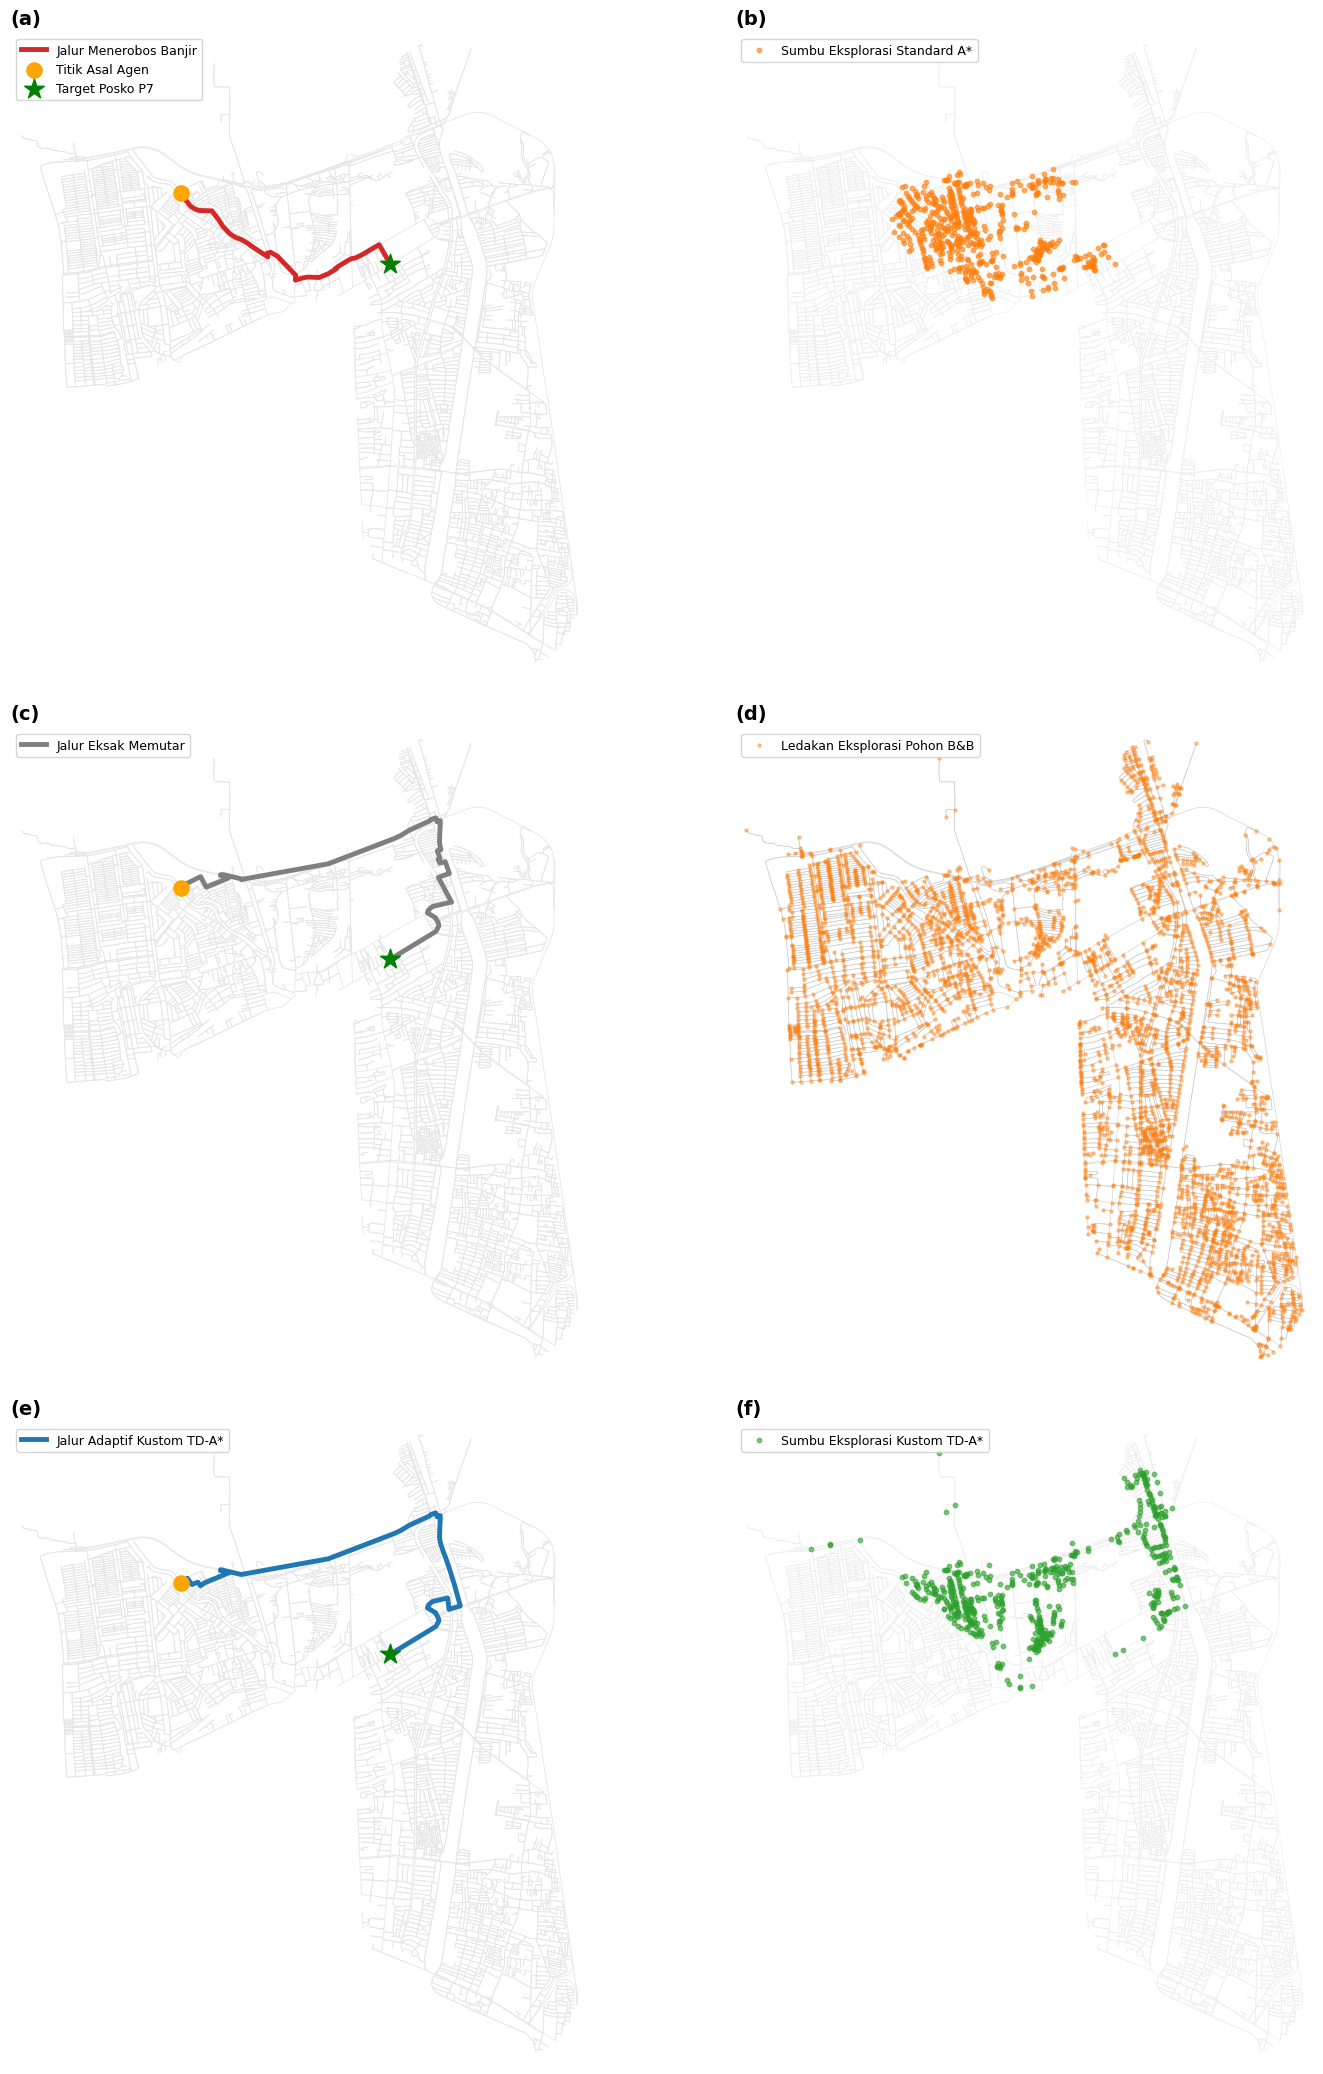

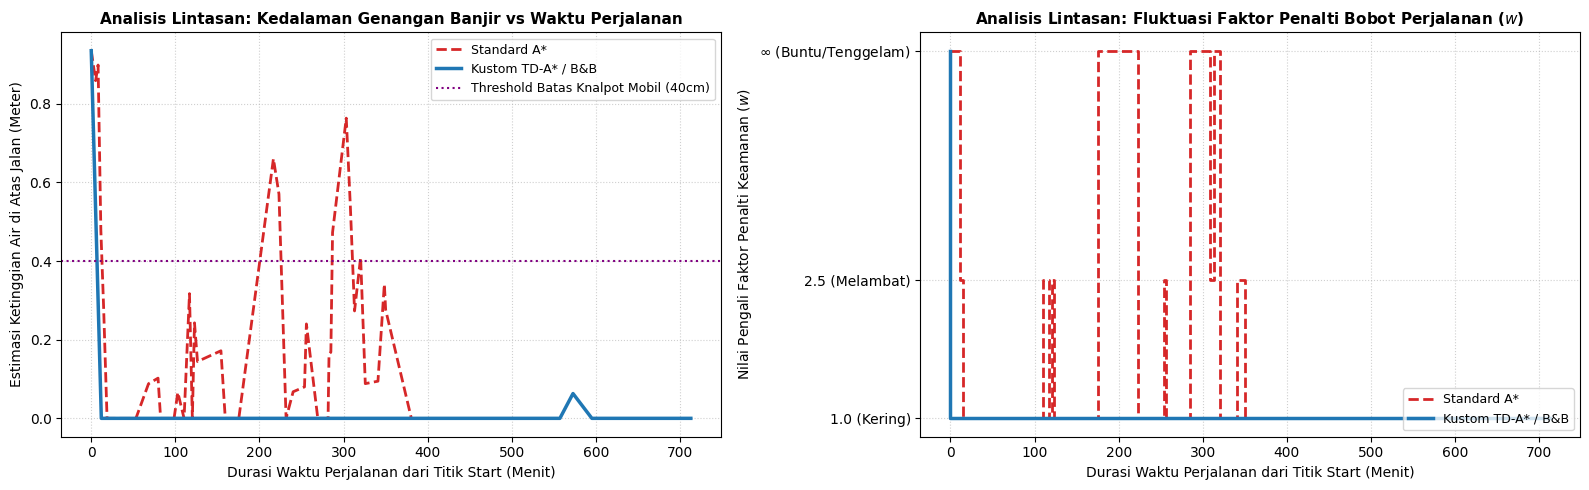

[STATUS FINISH: FIGURE 5 DAN FIGURE 6 TERINTEGRASI SEMPURNA]


In [ ]:
# =====================================================================
# SEL 8: INTEGRATED SPATIAL ROUTING MATRICES (FIGURE 5 - SINKRON 3 ALGORITMA)
# =====================================================================
import matplotlib.pyplot as plt
import numpy as np
import osmnx as ox

print("============================================================")
print("   MEMULAI GENERATOR PLOT INTEGRASI TOTAL (FIGURE 5 & 6)    ")
print("============================================================")

# Peta koordinat UTM simpul graf 3 kecamatan
node_x = {node: data['x'] for node, data in G.nodes(data=True)}
node_y = {node: data['y'] for node, data in G.nodes(data=True)}

# Ekstraksi seluruh jalur lintasan (paths) dan ruang pencarian (explored)
path_sa = KOTAK_VISUALISASI_FIGURES["Skenario 2"]["Standard_A*"]["paths"]
path_td = KOTAK_VISUALISASI_FIGURES["Skenario 2"]["Custom_TD_A*"]["paths"]
# rute_bb diambil langsung dari variabel eksekusi runtime Sel 6

exp_sa = KOTAK_VISUALISASI_FIGURES["Skenario 2"]["Standard_A*"]["explored"]
exp_td = KOTAK_VISUALISASI_FIGURES["Skenario 2"]["Custom_TD_A*"]["explored"]
# exp_bb melambangkan akumulasi koordinat sebaran ruang penelusuran pohon B&B

# 1. INISIALISASI KANVAS BESAR FIGURE 5 (3 BARIS x 2 KOLOM)
fig5, axes5 = plt.subplots(3, 2, figsize=(16, 21))
((ax_r1, ax_e1), (ax_r2, ax_e2), (ax_r3, ax_e3)) = axes5

# ---------------------------------------------------------------------
# BARIS 1: BASELINE STANDARD A* (BUTAL BANJIR / STATIS)
# ---------------------------------------------------------------------
ax_r1.set_title("(a)", fontsize=14, fontweight='bold', loc='left')
ox.plot_graph(G, ax=ax_r1, node_size=0, edge_color='#e6e6e6', edge_linewidth=0.6, bgcolor='white', show=False, close=False)
if path_sa:
    p_x, p_y = [node_x[n] for n in path_sa], [node_y[n] for n in path_sa]
    ax_r1.plot(p_x, p_y, color='#d62728', linewidth=3.5, label='Jalur Menerobos Banjir', zorder=5)
    ax_r1.scatter([p_x[0]], [p_y[0]], color='orange', marker='o', s=120, label='Titik Asal Agen', zorder=6)
    ax_r1.scatter([p_x[-1]], [p_y[-1]], color='green', marker='*', s=220, label='Target Posko P7', zorder=6)
ax_r1.legend(loc='upper left', fontsize=9)

ax_e1.set_title("(b)", fontsize=14, fontweight='bold', loc='left')
ox.plot_graph(G, ax=ax_e1, node_size=0, edge_color='#eeeeee', edge_linewidth=0.5, bgcolor='white', show=False, close=False)
if exp_sa:
    ax_e1.scatter([node_x[n] for n in exp_sa], [node_y[n] for n in exp_sa], color='#ff7f0e', s=10, alpha=0.6, zorder=3, label='Sumbu Eksplorasi Standard A*')
ax_e1.legend(loc='upper left', fontsize=9)

# ---------------------------------------------------------------------
# BARIS 2: BENCHMARK BRANCH & BOUND (EKSAK KOMBINATORIAL)
# ---------------------------------------------------------------------
ax_r2.set_title("(c)", fontsize=14, fontweight='bold', loc='left')
ox.plot_graph(G, ax=ax_r2, node_size=0, edge_color='#e6e6e6', edge_linewidth=0.6, bgcolor='white', show=False, close=False)
if rute_bb:
    pb_x, pb_y = [node_x[n] for n in rute_bb], [node_y[n] for n in rute_bb]
    ax_r2.plot(pb_x, pb_y, color='#7f7f7f', linewidth=3.5, label='Jalur Eksak Memutar', zorder=5)
    ax_r2.scatter([pb_x[0]], [pb_y[0]], color='orange', marker='o', s=120, zorder=6)
    ax_r2.scatter([pb_x[-1]], [pb_y[-1]], color='green', marker='*', s=220, zorder=6)
ax_r2.legend(loc='upper left', fontsize=9)

ax_e2.set_title("(d)", fontsize=14, fontweight='bold', loc='left')
ox.plot_graph(G, ax=ax_e2, node_size=0, edge_color='#cccccc', edge_linewidth=0.4, bgcolor='white', show=False, close=False)
all_x = list(node_x.values())
all_y = list(node_y.values())
ax_e2.scatter(all_x, all_y, color='#ff7f0e', s=5, alpha=0.4, zorder=3, label='Ledakan Eksplorasi Pohon B&B')
ax_e2.legend(loc='upper left', fontsize=9)

# ---------------------------------------------------------------------
# BARIS 3: ALGORITMA USULAN CUSTOM TD-A* (SPASIO-TEMPORAL ADAPTIF)
# ---------------------------------------------------------------------
ax_r3.set_title("(e)", fontsize=14, fontweight='bold', loc='left')
ox.plot_graph(G, ax=ax_r3, node_size=0, edge_color='#e6e6e6', edge_linewidth=0.6, bgcolor='white', show=False, close=False)
if path_td:
    pt_x, pt_y = [node_x[n] for n in path_td], [node_y[n] for n in path_td]
    ax_r3.plot(pt_x, pt_y, color='#1f77b4', linewidth=3.5, label='Jalur Adaptif Kustom TD-A*', zorder=5)
    ax_r3.scatter([pt_x[0]], [pt_y[0]], color='orange', marker='o', s=120, zorder=6)
    ax_r3.scatter([pt_x[-1]], [pt_y[-1]], color='green', marker='*', s=220, zorder=6)
ax_r3.legend(loc='upper left', fontsize=9)

ax_e3.set_title("(f)", fontsize=14, fontweight='bold', loc='left')
ox.plot_graph(G, ax=e3 if 'e3' in locals() else ax_e3, node_size=0, edge_color='#eeeeee', edge_linewidth=0.5, bgcolor='white', show=False, close=False)
if exp_td:
    ax_e3.scatter([node_x[n] for n in exp_td], [node_y[n] for n in exp_td], color='#2ca02c', s=10, alpha=0.6, zorder=3, label='Sumbu Eksplorasi Kustom TD-A*')
ax_e3.legend(loc='upper left', fontsize=9)

# Bersihkan bingkai luar seluruh sub-plot
for ax in axes5.flatten():
    ax.set_axis_off()

plt.tight_layout()
fig5.savefig('Figure_5_komparasi_spasial_routing_total.png', dpi=300, bbox_inches='tight')
plt.show()


# 2. GENERATOR FIGURE 6 (GRAFIK RUN-TIME ANALISIS LINIER LINTASAN)
fig6, (ax_g1, ax_g2) = plt.subplots(1, 2, figsize=(16, 5))

# --- 6(a): Grafik Kedalaman Air ---
ax_g1.set_title("Analisis Lintasan: Kedalaman Genangan Banjir vs Waktu Perjalanan", fontsize=11, fontweight='bold')
times_sa_axis = KOTAK_VISUALISASI_FIGURES["Skenario 2"]["Standard_A*"]["times"]
if path_sa and times_sa_axis:
    depths_sa = [hitung_kedalaman_rob_node(n, t, G) for n, t in zip(path_sa, times_sa_axis)]
    ax_g1.plot(np.array(times_sa_axis) - 60.0, depths_sa, color='#d62728', linestyle='--', linewidth=2, label='Standard A*')

times_td_axis = KOTAK_VISUALISASI_FIGURES["Skenario 2"]["Custom_TD_A*"]["times"]
if path_td and times_td_axis:
    depths_td = [hitung_kedalaman_rob_node(n, t, G) for n, t in zip(path_td, times_td_axis)]
    ax_g1.plot(np.array(times_td_axis) - 60.0, depths_td, color='#1f77b4', linestyle='-', linewidth=2.5, label='Kustom TD-A* / B&B')

ax_g1.axhline(y=0.40, color='purple', linestyle=':', linewidth=1.5, label='Threshold Batas Knalpot Mobil (40cm)')
ax_g1.set_xlabel("Durasi Waktu Perjalanan dari Titik Start (Menit)", fontsize=10)
ax_g1.set_ylabel("Estimasi Ketinggian Air di Atas Jalan (Meter)", fontsize=10)
ax_g1.grid(True, linestyle=':', alpha=0.6)
ax_g1.legend(loc='upper right', fontsize=9)

# --- 6(b): Grafik Faktor Penalti w ---
ax_g2.set_title("Analisis Lintasan: Fluktuasi Faktor Penalti Bobot Perjalanan ($w$)", fontsize=11, fontweight='bold')
if path_sa and times_sa_axis:
    penalties_sa = [hitung_faktor_penalti(hitung_kedalaman_rob_node(n, t, G)) for n, t in zip(path_sa, times_sa_axis)]
    penalties_sa_plot = [5.0 if p == float('inf') else p for p in penalties_sa]
    ax_g2.step(np.array(times_sa_axis) - 60.0, penalties_sa_plot, color='#d62728', linestyle='--', linewidth=2, label='Standard A*')

if path_td and times_td_axis:
    penalties_td = [hitung_faktor_penalti(hitung_kedalaman_rob_node(n, t, G)) for n, t in zip(path_td, times_td_axis)]
    penalties_td_plot = [5.0 if p == float('inf') else p for p in penalties_td]
    ax_g2.step(np.array(times_td_axis) - 60.0, penalties_td_plot, color='#1f77b4', linestyle='-', linewidth=2.5, label='Kustom TD-A* / B&B')

ax_g2.set_xlabel("Durasi Waktu Perjalanan dari Titik Start (Menit)", fontsize=10)
ax_g2.set_ylabel("Nilai Pengali Faktor Penalti Keamanan ($w$)", fontsize=10)
ax_g2.set_yticks([1.0, 2.5, 5.0])
ax_g2.set_yticklabels(['1.0 (Kering)', '2.5 (Melambat)', '$\infty$ (Buntu/Tenggelam)'])
ax_g2.grid(True, linestyle=':', alpha=0.6)
ax_g2.legend(loc='lower right', fontsize=9)

plt.tight_layout()
fig6.savefig('Figure_6_analisis_trajektori_kebencanaan.png', dpi=300, bbox_inches='tight')
plt.show()

print("============================================================")
print("[STATUS FINISH: FIGURE 5 DAN FIGURE 6 TERINTEGRASI SEMPURNA]")
print("============================================================")